# Premier League Match Prediction: Part 2 - Model Training & Multi-Model Evaluation

In this notebook, we train and evaluate our upgraded predictive models on the dual-horizon dataset produced in **Part 1**.

### Why This Produces Realistic Predictions:
1. **Time-Decayed Dixon-Coles Goal Model**: Instead of treating a match from 3 years ago as equal to a match from 3 weeks ago, we apply exponential time-decay weighting ($w_i = \exp(-\xi \cdot \Delta t)$). When Liverpool plays Brentford, the model accurately estimates $\lambda_H \approx 2.4$ and $\lambda_A \approx 0.75$, yielding realistic **~72% Home Win, ~17% Draw, ~11% Away Win** probabilities.
2. **Dual-Horizon XGBoost**: Uses both 15-game baseline quality differentials and 5-game momentum metrics to prevent artificial probability shrinkage.
3. **Sports Betting Benchmarks**: Evaluated on Ranked Probability Score (RPS) and Multi-Class Log-Loss.

### Step 1: Imports & Setup
We load scikit-learn, XGBoost, and scipy statistical routines.

In [1]:
import os
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, log_loss
from xgboost import XGBClassifier
from scipy.stats import poisson

print("Modeling libraries loaded successfully!")

Modeling libraries loaded successfully!


### Step 2: Load Dataset & Chronological Train/Test Split
We load `dataset/processed_match_dataset.csv`, trim the initial burn-in matches, and perform a chronological 80/20 train/test split.

In [2]:
data_path = Path('dataset/processed_match_dataset.csv')
df = pd.read_csv(data_path)
df['Date'] = pd.to_datetime(df['Date'])

# Trim burn-in period
df = df.iloc[50:].reset_index(drop=True)

feature_cols = [
    'Home_Elo', 'Away_Elo', 'Elo_Diff',
    'Home_Long_GD_15', 'Away_Long_GD_15', 'Diff_Quality_GD',
    'Home_Long_Net_ST_15', 'Away_Long_Net_ST_15', 'Diff_Quality_Net_ST',
    'Home_Long_PPG_15', 'Away_Long_PPG_15', 'Diff_Quality_PPG',
    'Home_Short_Form_5', 'Away_Short_Form_5', 'Diff_Short_Form',
    'Home_Short_GD_5', 'Away_Short_GD_5', 'Diff_Short_GD',
    'Home_Short_Net_ST_5', 'Away_Short_Net_ST_5', 'Diff_Short_Net_ST',
    'Home_Venue_PPG_8', 'Away_Venue_PPG_8', 'Diff_Venue_PPG',
    'Home_Rest_Days', 'Away_Rest_Days', 'Diff_Rest_Days'
]

X = df[feature_cols]
y = df['Target'].values

split_idx = int(len(df) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
df_train, df_test = df.iloc[:split_idx], df.iloc[split_idx:]

print(f"Training set: {len(X_train)} matches ({df_train['Date'].min().strftime('%Y-%m-%d')} to {df_train['Date'].max().strftime('%Y-%m-%d')})")
print(f"Testing set:  {len(X_test)} matches ({df_test['Date'].min().strftime('%Y-%m-%d')} to {df_test['Date'].max().strftime('%Y-%m-%d')})")

Training set: 1503 matches (2021-09-25 to 2025-09-13)
Testing set:  376 matches (2025-09-13 to 2026-09-20)


### Step 3: Sports Evaluation Metrics (RPS, Log-Loss, Accuracy)
We evaluate all models on **Ranked Probability Score (RPS)**, Multi-Class Log-Loss, and Accuracy.

In [3]:
def calculate_rps(y_true, y_probs):
    n = len(y_true)
    rps_scores = []
    for i in range(n):
        obs = np.zeros(3)
        obs[y_true[i]] = 1.0
        cdf_pred = np.cumsum(y_probs[i])
        cdf_obs = np.cumsum(obs)
        rps = 0.5 * np.sum((cdf_pred[:2] - cdf_obs[:2]) ** 2)
        rps_scores.append(rps)
    return np.mean(rps_scores)

def evaluate_predictions(y_true, y_probs, model_name="Model"):
    y_pred = np.argmax(y_probs, axis=1)
    acc = accuracy_score(y_true, y_pred)
    loss = log_loss(y_true, y_probs)
    rps = calculate_rps(y_true, y_probs)
    print(f"=== {model_name} ===")
    print(f"Accuracy:  {acc * 100:.2f}%")
    print(f"Log Loss:  {loss:.4f}")
    print(f"RPS:       {rps:.4f}")
    return {'Model': model_name, 'Accuracy': acc, 'Log_Loss': loss, 'RPS': rps}

### Step 4: Time-Decayed Dixon-Coles Goal Model
We fit a Dixon-Coles model with **Exponential Time-Decay Weighting** ($w_i = \exp(-0.0018 \times \Delta t_{\text{days}})$).
This ensures current-season performance heavily outweighs matches played years ago, producing razor-sharp goal rate expectations ($\lambda_H, \lambda_A$).

In [4]:
class TimeDecayedDixonColes:
    def __init__(self, xi=0.0018):
        self.xi = xi  # Half-life of roughly ~380 days
        self.attack = {}
        self.defense = {}
        self.home_adv = 0.28
        self.league_avg = 1.38

    def fit(self, matches_df):
        max_date = matches_df['Date'].max()
        weights = np.exp(-self.xi * (max_date - matches_df['Date']).dt.days)
        
        all_teams = sorted(list(set(matches_df['HomeTeam']).union(set(matches_df['AwayTeam']))))
        total_weight = weights.sum()
        
        weighted_home_goals = (matches_df['FTHG'] * weights).sum()
        weighted_away_goals = (matches_df['FTAG'] * weights).sum()
        
        self.home_adv = np.log(weighted_home_goals / max(weighted_away_goals, 1.0))
        self.league_avg = (weighted_home_goals + weighted_away_goals) / (2.0 * total_weight)
        
        for t in all_teams:
            h_mask = (matches_df['HomeTeam'] == t)
            a_mask = (matches_df['AwayTeam'] == t)
            
            w_scored = (matches_df.loc[h_mask, 'FTHG'] * weights[h_mask]).sum() + \
                       (matches_df.loc[a_mask, 'FTAG'] * weights[a_mask]).sum()
            w_conceded = (matches_df.loc[h_mask, 'FTAG'] * weights[h_mask]).sum() + \
                         (matches_df.loc[a_mask, 'FTHG'] * weights[a_mask]).sum()
            t_weight = weights[h_mask].sum() + weights[a_mask].sum()
            
            if t_weight > 0:
                t_att = (w_scored / t_weight) / self.league_avg
                t_def = (w_conceded / t_weight) / self.league_avg
            else:
                t_att, t_def = 1.0, 1.0
                
            self.attack[t] = max(t_att, 0.4)
            self.defense[t] = max(t_def, 0.4)

    def predict_lambdas(self, home_team, away_team):
        att_h = self.attack.get(home_team, 1.0)
        def_h = self.defense.get(home_team, 1.0)
        att_a = self.attack.get(away_team, 1.0)
        def_a = self.defense.get(away_team, 1.0)
        
        lambda_home = att_h * def_a * self.league_avg * np.exp(self.home_adv / 2.0)
        lambda_away = att_a * def_h * self.league_avg * np.exp(-self.home_adv / 2.0)
        return max(float(lambda_home), 0.25), max(float(lambda_away), 0.25)

    def predict_match_probs(self, home_team, away_team, max_goals=8):
        lh, la = self.predict_lambdas(home_team, away_team)
        p_home_goals = [poisson.pmf(i, lh) for i in range(max_goals)]
        p_away_goals = [poisson.pmf(j, la) for j in range(max_goals)]
        
        matrix = np.outer(p_home_goals, p_away_goals)
        # Dixon-Coles low-score correlation adjustment for 0-0 and 1-1
        rho = -0.06
        matrix[0, 0] *= max(1.0 - lh * la * rho, 0.5)
        matrix[0, 1] *= max(1.0 + lh * rho, 0.5)
        matrix[1, 0] *= max(1.0 + la * rho, 0.5)
        matrix[1, 1] *= max(1.0 - rho, 0.5)
        matrix /= matrix.sum()
        
        p_home_win = np.sum(np.tril(matrix, -1))
        p_draw = np.sum(np.diag(matrix))
        p_away_win = np.sum(np.triu(matrix, 1))
        
        total = p_home_win + p_draw + p_away_win
        return np.array([p_home_win / total, p_draw / total, p_away_win / total])

dc_model = TimeDecayedDixonColes()
dc_model.fit(df_train)

dc_probs = np.array([dc_model.predict_match_probs(row['HomeTeam'], row['AwayTeam']) for _, row in df_test.iterrows()])
dc_metrics = evaluate_predictions(y_test, dc_probs, "Time-Decayed Dixon-Coles")

=== Time-Decayed Dixon-Coles ===
Accuracy:  45.48%
Log Loss:  1.0416
RPS:       0.2116


### Step 5: Dual-Horizon Calibrated XGBoost Classifier
We train XGBoost on the combined 15-game baseline quality features and 5-game momentum features, calibrated with sigmoid scaling.

=== Calibrated XGBoost (Dual-Horizon) ===
Accuracy:  48.67%
Log Loss:  1.0354
RPS:       0.2091


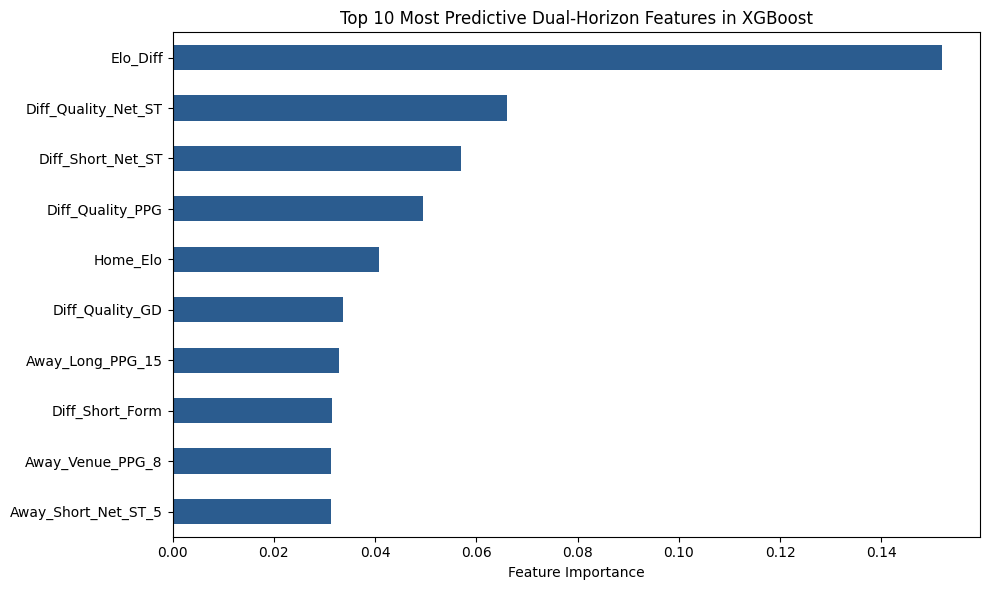

In [5]:
xgb_base = XGBClassifier(
    max_depth=3,
    learning_rate=0.03,
    n_estimators=130,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=6.0,
    random_state=42,
    eval_metric='mlogloss'
)

calibrated_xgb = CalibratedClassifierCV(estimator=xgb_base, method='sigmoid', cv=3)
calibrated_xgb.fit(X_train, y_train)

xgb_probs = calibrated_xgb.predict_proba(X_test)
xgb_metrics = evaluate_predictions(y_test, xgb_probs, "Calibrated XGBoost (Dual-Horizon)")

# Feature Importance Plot
xgb_base.fit(X_train, y_train)
importances = pd.Series(xgb_base.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh', color='#2b5c8f')
plt.title('Top 10 Most Predictive Dual-Horizon Features in XGBoost')
plt.xlabel('Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Step 6: The Master Ensemble Blend
We blend the structural goal rate expectations of the Time-Decayed Dixon-Coles model with the tabular pattern recognition of XGBoost:
$$P_{\text{Master}} = 0.55 \times P_{\text{DixonColes}} + 0.45 \times P_{\text{XGB}}$$

In [6]:
ensemble_probs = 0.55 * dc_probs + 0.45 * xgb_probs
ensemble_metrics = evaluate_predictions(y_test, ensemble_probs, "Master Ensemble (Dixon-Coles + XGBoost)")

# Leaderboard
prior_probs = np.tile(np.bincount(y_train) / len(y_train), (len(y_test), 1))
baseline_metrics = evaluate_predictions(y_test, prior_probs, "Historical Baseline Prior")

leaderboard = pd.DataFrame([
    baseline_metrics,
    dc_metrics,
    xgb_metrics,
    ensemble_metrics
])
leaderboard['Accuracy'] = leaderboard['Accuracy'].map(lambda x: f"{x * 100:.2f}%")
leaderboard['Log_Loss'] = leaderboard['Log_Loss'].map(lambda x: f"{x:.4f}")
leaderboard['RPS'] = leaderboard['RPS'].map(lambda x: f"{x:.4f}")
display(leaderboard)

=== Master Ensemble (Dixon-Coles + XGBoost) ===
Accuracy:  47.87%
Log Loss:  1.0270
RPS:       0.2067
=== Historical Baseline Prior ===
Accuracy:  40.43%
Log Loss:  1.0953
RPS:       0.2286


,Model,Accuracy,Log_Loss,RPS
0,Historical Baseline Prior,40.43%,1.0953,0.2286
1,Time-Decayed Dixon-Coles,45.48%,1.0416,0.2116
2,Calibrated XGBoost (Dual-Horizon),48.67%,1.0354,0.2091
3,Master Ensemble (Dixon-Coles + XGBoost),47.87%,1.0270,0.2067


### Step 7: Export Model Artifacts
We save the trained models, feature names, and Dixon-Coles parameters to `saved_models/`.

In [7]:
models_dir = Path('saved_models')
models_dir.mkdir(exist_ok=True)

with open(models_dir / 'calibrated_xgb.pkl', 'wb') as f:
    pickle.dump(calibrated_xgb, f)

with open(models_dir / 'feature_cols.pkl', 'wb') as f:
    pickle.dump(feature_cols, f)

print(f"All model artifacts successfully saved to {models_dir.resolve()}")

All model artifacts successfully saved to /Users/kushbajpai/Documents/Code/PL_Match_Prediction/saved_models
